# 07 · Matriz de conformidade: requisito, controle, evidência

**Objetivo:** fechar o ciclo. Para cada requisito de sistema da **IEC 62443-3-3** usado no lab, mostrar qual controle o atende, qual teste prova isso, e o status **calculado a partir de uma execução real dos testes**. Depois, ver os mesmos controles pelas funções do **NIST CSF 2.0**.

É a ideia de **compliance as code**: a trilha de auditoria é o próprio CI. Se alguém desligar o TLS do broker, o teste falha e o requisito deixa de aparecer como atendido.

### Antes de começar

| | |
|---|---|
| **Para quem** | Quem precisa mostrar a um cliente ou auditor o que foi feito, com evidência. |
| **Pré-requisitos** | Notebooks 00 a 06. |
| **Tempo** | 30 minutos |

**Ao final você consegue:**

- Ligar cada requisito a um controle e a uma evidência verificável.
- Explicar a ideia de conformidade como código.
- Diferenciar atendido, parcial, planejado e lacuna.
- Ler os mesmos controles pela 62443-3-3 e pelo NIST CSF 2.0.

**Onde isso aparece na fábrica:** O entregável final de um projeto de segurança é a matriz de conformidade. Quando a evidência é um teste automático, ela não envelhece: se alguém desfaz um controle, a matriz acusa.

**Uma analogia para guardar:** É o laudo de vistoria do prédio, mas com um vistoriador que passa de novo toda noite. Um extintor retirado aparece no laudo do dia seguinte, sem esperar a próxima auditoria anual.

> **Como estudar:** rode uma célula por vez. Sempre que aparecer **Pare e preveja**, responda mentalmente antes de executar. Errar a previsão é o que faz o conceito fixar.

In [1]:
# Configuração: raiz do repositório no caminho de import, tabelas largas
import sys, pathlib, logging, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
from IPython.display import Image, Markdown, display
from otsec.model import CAPTURES
from otsec import compliance as comp, figures
resultados = comp.run_tests()
print(f"testes executados: {len(resultados)} | passaram: {sum(resultados.values())}")
pd.Series(resultados, name="passou").to_frame()

testes executados: 19 | passaram: 19


,passou
tests/test_hardening.py::test_mqtt_anonymous_rejected,True
tests/test_hardening.py::test_mqtt_tls_required,True
tests/test_hardening.py::test_credentials_not_visible_on_the_wire,True
tests/test_hardening.py::test_mqtt_acl,True
tests/test_hardening.py::test_password_policy,True
tests/test_hardening.py::test_opcua_rejects_insecure,True
tests/test_hardening.py::test_opcua_secure_session,True
tests/test_ids.py::test_no_false_positives_on_normal_day,True
tests/test_ids.py::test_detects_every_technique,True
tests/test_inventory.py::test_inventory_matches_documented_assets,True


## 1. Status dos controles

In [2]:
ctl = comp.control_status(resultados)
cor = {"met": "#d5f5e3", "planned": "#fcf3cf", "evidence failing": "#fadbd8"}
ctl.style.map(lambda v: f"background-color: {cor.get(v, '')}", subset=["status"])

,control,name,exercise,status,evidence,62443-3-3,NIST CSF 2.0,ATT&CK mitigations
0,CTL-INV,Passive asset inventory from network captures,01,met,2/2 tests,SR 7.8,"ID.AM-01, ID.AM-03",
1,CTL-ZONES,Zone and conduit model with design rules,02,met,2/2 tests,SR 5.1,"ID.AM-03, PR.IR-01",M0930
2,CTL-FW,Default-deny firewall between zones generated from the conduits,04,met,2/2 tests,"SR 5.1, SR 5.2, SR 2.1","PR.IR-01, PR.AA-05","M0930, M0937, M0807"
3,CTL-DMZ,Enterprise reaches plant data only through the DMZ broker,04,met,1/1 tests,"SR 5.2, SR 1.13",PR.IR-01,M0930
4,CTL-MQTT-TLS,MQTT over TLS with a private CA,05,met,1/1 tests,"SR 3.1, SR 4.1, SR 4.3, SR 1.8",PR.DS-02,"M0808, M0802"
5,CTL-MQTT-AUTH,"MQTT without anonymous access, one account per client, strong passwords",05,met,2/2 tests,"SR 1.1, SR 1.5, SR 1.7","PR.AA-01, PR.AA-03","M0804, M0927"
6,CTL-MQTT-ACL,Per-topic ACL on the UNS broker,05,met,1/1 tests,SR 2.1,PR.AA-05,M0800
7,CTL-OPCUA-SEC,"OPC UA with SignAndEncrypt, application certificates and user login",05,met,2/2 tests,"SR 1.1, SR 1.2, SR 1.8, SR 3.1, SR 4.1","PR.AA-01, PR.DS-02","M0813, M0802, M0808"
8,CTL-IDS,"Modbus allowlist IDS (talkers, function codes, write ranges, rates)",06,met,2/2 tests,"SR 6.2, SR 2.8, SR 7.1","DE.CM-01, DE.AE-02",M0931
9,CTL-MFA,MFA and a jump host for remote access,-,planned,none,SR 1.13,PR.AA-03,M0932


Nove controles implementados com toda a evidência passando, quatro **planejados**. Os planejados não são esquecimentos: vieram da avaliação de risco do exercício 03 (mídia removível, download de programa, MFA, backup, logs centralizados).

## 2. A matriz da 62443-3-3

> **Pare e preveja.** O laboratório implementou nove controles. Você espera que todos os requisitos apareçam como atendidos, ou que alguns fiquem parciais ou planejados? Quais?

In [3]:
m = comp.matrix(resultados)
cor = {"met": "#d5f5e3", "partial": "#d6eaf8", "planned": "#fcf3cf", "gap": "#fadbd8"}
m.style.map(lambda v: f"background-color: {cor.get(v, '')}", subset=["status"])

,SR,FR,requirement,controls,status
0,SR 1.1,IAC,Human user identification and authentication,"CTL-MQTT-AUTH, CTL-OPCUA-SEC",met
1,SR 1.2,IAC,Software process and device identification and authentication,CTL-OPCUA-SEC,met
2,SR 1.5,IAC,Authenticator management,CTL-MQTT-AUTH,met
3,SR 1.7,IAC,Strength of password-based authentication,CTL-MQTT-AUTH,met
4,SR 1.8,IAC,Public key infrastructure certificates,"CTL-MQTT-TLS, CTL-OPCUA-SEC",met
5,SR 1.13,IAC,Access via untrusted networks,"CTL-DMZ, CTL-MFA",partial
6,SR 2.1,UC,Authorization enforcement,"CTL-FW, CTL-MQTT-ACL",met
7,SR 2.8,UC,Auditable events,CTL-IDS,met
8,SR 3.1,SI,Communication integrity,"CTL-MQTT-TLS, CTL-OPCUA-SEC",met
9,SR 3.2,SI,Malicious code protection,CTL-ALLOWLIST,planned


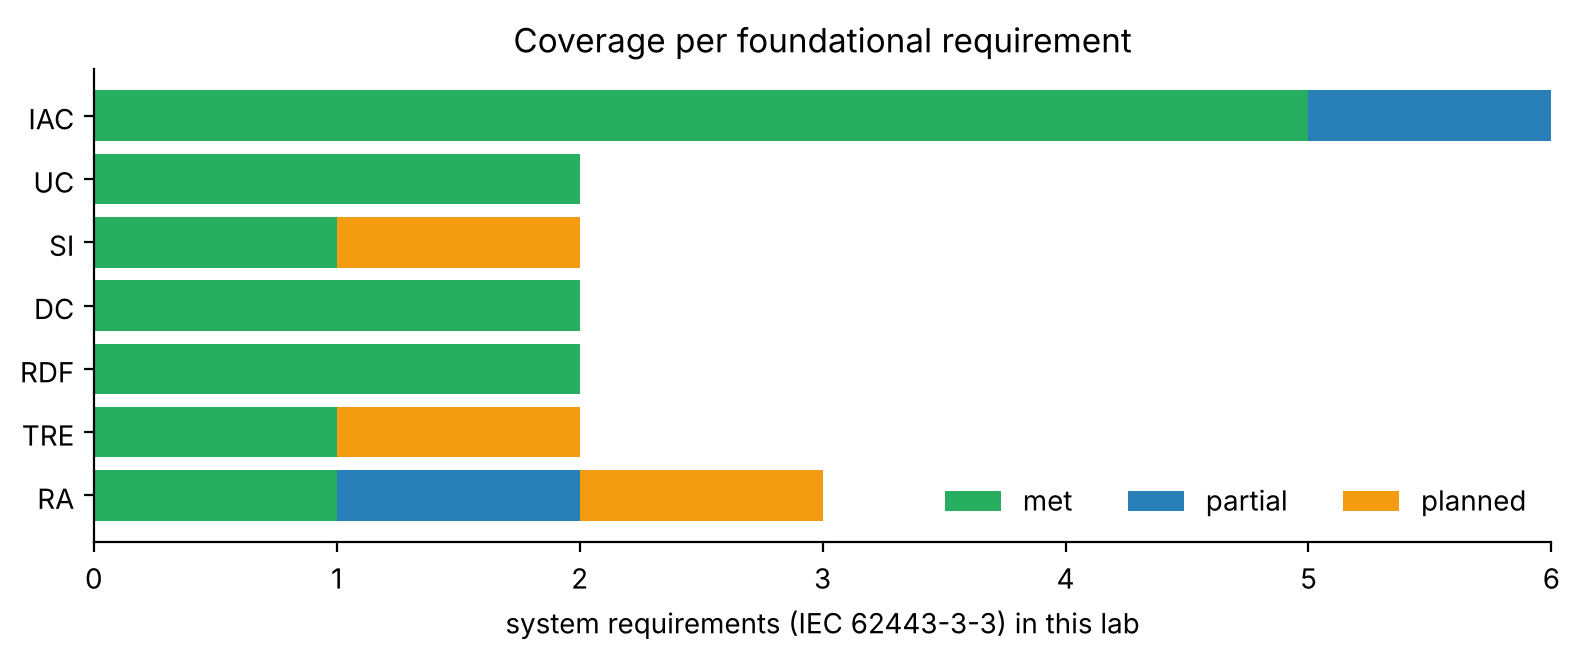

In [4]:
fig = comp.chart(m); figures.save(fig, "compliance"); plt.show()

**Leitura:**

* **RDF (fluxo restrito)** totalmente coberto: é o que segmentação e DMZ entregam.
* **SR 1.13 e SR 7.1 aparecem como parciais.** A DMZ elimina o caminho direto, mas acesso remoto sem MFA não fecha o requisito. O IDS **detecta** um flood mas não o **limita**. Marcar como "atendido" seria otimismo de auditoria.
* **SR 3.2, 6.1 e 7.3** dependem dos controles planejados.

## 3. Os mesmos controles pelo NIST CSF 2.0

> **Pare e preveja.** A 62443 pede muita proteção e detecção. Olhando pelas funções do NIST CSF (identificar, proteger, detectar, responder, recuperar), onde você acha que o laboratório está mais fraco?

In [5]:
csf = comp.csf(resultados)
pivot = csf.groupby(["function", "status"]).size().unstack(fill_value=0)
display(pivot)
csf

status,met,planned
function,,
Detect,2,1
Identify,3,0
Protect,10,4
Recover,0,1


,function,subcategory,control,status
14,Detect,DE.AE-02,CTL-IDS,met
13,Detect,DE.CM-01,CTL-IDS,met
20,Detect,DE.CM-01,CTL-SIEM,planned
0,Identify,ID.AM-01,CTL-INV,met
1,Identify,ID.AM-03,CTL-INV,met
2,Identify,ID.AM-03,CTL-ZONES,met
8,Protect,PR.AA-01,CTL-MQTT-AUTH,met
11,Protect,PR.AA-01,CTL-OPCUA-SEC,met
9,Protect,PR.AA-03,CTL-MQTT-AUTH,met
15,Protect,PR.AA-03,CTL-MFA,planned


O CSF mostra o que a 62443 deixa implícito: o lab é forte em **Identify, Protect e Detect** e não tem nada em **Respond** e quase nada em **Recover** (só o backup planejado). Um programa completo precisaria de plano de resposta a incidentes OT, exercícios de mesa e restauração testada de CLPs.

## 4. Exportando para quem não abre notebook

In [6]:
md = "| SR | Requisito | Controles | Status |\n|---|---|---|---|\n" + "\n".join(
    f"| {r.SR} | {r.requirement} | {r.controls} | {r.status} |" for r in m.itertuples())
(figures.IMG.parent / "compliance_matrix.md").write_text("# Compliance matrix (generated)\n\n" + md + "\n")
display(Markdown(md))

| SR | Requisito | Controles | Status |
|---|---|---|---|
| SR 1.1 | Human user identification and authentication | CTL-MQTT-AUTH, CTL-OPCUA-SEC | met |
| SR 1.2 | Software process and device identification and authentication | CTL-OPCUA-SEC | met |
| SR 1.5 | Authenticator management | CTL-MQTT-AUTH | met |
| SR 1.7 | Strength of password-based authentication | CTL-MQTT-AUTH | met |
| SR 1.8 | Public key infrastructure certificates | CTL-MQTT-TLS, CTL-OPCUA-SEC | met |
| SR 1.13 | Access via untrusted networks | CTL-DMZ, CTL-MFA | partial |
| SR 2.1 | Authorization enforcement | CTL-FW, CTL-MQTT-ACL | met |
| SR 2.8 | Auditable events | CTL-IDS | met |
| SR 3.1 | Communication integrity | CTL-MQTT-TLS, CTL-OPCUA-SEC | met |
| SR 3.2 | Malicious code protection | CTL-ALLOWLIST | planned |
| SR 4.1 | Information confidentiality | CTL-MQTT-TLS, CTL-OPCUA-SEC | met |
| SR 4.3 | Use of cryptography | CTL-MQTT-TLS | met |
| SR 5.1 | Network segmentation | CTL-ZONES, CTL-FW | met |
| SR 5.2 | Zone boundary protection | CTL-FW, CTL-DMZ | met |
| SR 6.1 | Audit log accessibility | CTL-SIEM | planned |
| SR 6.2 | Continuous monitoring | CTL-IDS | met |
| SR 7.1 | Denial of service protection | CTL-IDS | partial |
| SR 7.3 | Control system backup | CTL-BACKUP | planned |
| SR 7.8 | Control system component inventory | CTL-INV | met |

A tabela vai para `docs/compliance_matrix.md`, que é o que um integrador entregaria ao cliente junto com o relatório de testes.

## Resumo do lab inteiro

| Etapa | O que fizemos | Evidência |
|---|---|---|
| 01 Inventário | descoberta passiva, RDP esquecido, senha em claro, intruso | `test_inventory.py` |
| 02 Zonas | modelo Purdue como código, 4 violações no tráfego real | `test_zones.py` |
| 03 Risco | 12 ameaças do ATT&CK for ICS, inerente → residual, SL-T × SL-A | `test_risk.py` |
| 04 Segmentação | firewall gerado do modelo, conexões reais bloqueadas | `test_segmentation.py` |
| 05 Hardening | MQTT TLS + ACL, OPC UA SignAndEncrypt + certificados | `test_hardening.py` |
| 06 Detecção | IDS allowlist, 6/6 técnicas, 0 falsos positivos | `test_ids.py` |
| 07 Conformidade | matriz 62443-3-3 e CSF 2.0 gerada da execução dos testes | este notebook |

---
## Erros comuns

- **Evidência em captura de tela.** Ela prova como estava naquele dia. Um teste automático prova como está agora.
- **Marcar parcial como atendido.** Detectar uma inundação não é limitar a inundação. Otimismo na matriz vira surpresa na auditoria.
- **Olhar por uma norma só.** A 62443 não deixa evidente a falta de resposta e recuperação. Cruzar com o CSF mostra a lacuna.
- **Matriz sem dono nem data.** Cada lacuna precisa de responsável e prazo, ou vira lista esquecida.

## Teste seu entendimento

Responda antes de abrir cada resposta.

**1. O que acontece com a matriz se alguém desligar o TLS do broker?**

<details><summary>Ver resposta</summary>

O teste de evidência falha e os requisitos sustentados por esse controle deixam de aparecer como atendidos na próxima execução.

</details>

**2. Por que a proteção contra negação de serviço aparece como parcial?**

<details><summary>Ver resposta</summary>

Porque o detector percebe a inundação, mas nada limita a taxa de requisições. Falta um controle que impeça, e não só avise.

</details>

**3. O que a visão pelo NIST CSF revelou que a matriz da 62443 não deixava claro?**

<details><summary>Ver resposta</summary>

Que o laboratório cobre bem identificar, proteger e detectar, mas não tem nada em responder e quase nada em recuperar.

</details>

## Exercícios para praticar

1. Quebre de propósito um teste de evidência e gere a matriz de novo. Quais linhas mudam de status?
2. Escolha um controle planejado e escreva qual teste automático serviria de evidência para ele.
3. Monte o esboço de um plano de resposta a incidente OT em cinco passos para cobrir a função Respond.

## Glossário

| Termo | Significado |
|---|---|
| **Controle** | Medida implementada para atender um requisito. |
| **Evidência** | Prova verificável de que o controle funciona. |
| **Conformidade como código** | Requisitos, controles e testes mantidos em arquivos versionados e verificados automaticamente. |
| **CI** | Integração contínua: os testes rodam a cada mudança. |
| **Lacuna (gap)** | Requisito sem controle que o atenda. |
| **NIST CSF** | Estrutura que organiza um programa de cibersegurança em seis funções. |

**Próximo passo:** Você fechou o laboratório. Para voltar à base dos protocolos protegidos aqui, veja o [iiot-protocols-examples](https://github.com/MatheusEduGarcia/iiot-protocols-examples).